<a href="https://colab.research.google.com/github/Existanze54/sirius-machine-learning-2026/blob/main/Homeworks/HW6_GB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашка 6. Бустинг

### imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import SplineTransformer

from sklearn.linear_model import LinearRegression

from lightgbm import LGBMRegressor

## Задача 1. Бустинг на сплайнах

### Генерация данных

Возьмём знакомую функцию из второй домашки. Для обучения и валидации независимо выберем случайные точки и добавим к ним нормальный шум. Валидационную выборку сделаем больше, чтобы оценка ошибки была стабильнее.

In [ ]:
def f(x):
    return np.sin(3 * x) * np.exp(-(x / 1.5)**2)

x = np.arange(-3, 3.01, 0.01)
y = f(x)

rng = np.random.RandomState(3)

x_train = rng.uniform(-2.5, 2.51, 75)
y_train = f(x_train) + rng.normal(0, 0.15, len(x_train))

x_val = rng.uniform(-2.5, 2.51, 200)
y_val = f(x_val) + rng.normal(0, 0.15, len(x_val))

### Сплайны

**Сплайн** — это функция, склеенная из полиномов на соседних отрезках; точки их стыка называются **узлами**.

На графиках ниже сравним два варианта. Слева показан кубический сплайн, который `SplineTransformer` строит по умолчанию: он даёт плавную кривую, но с базовыми настройками не успевает повторить резкие изгибы функции. Справа — совсем простая ломаная из `fit_best_spline` с одним внутренним узлом, выбранным по наименьшей MSE из 15 равноотстоящих позиций. В одиночку она может согнуться лишь в одной точке и даёт грубый прогноз, но именно такие простые модели мы и будем складывать в бустинге.

In [ ]:
def fit_best_spline(x_train, target):
    X_train = x_train.reshape(-1, 1)
    left, right = x_train.min(), x_train.max()
    candidates = []

    for knot in np.linspace(left, right, 17)[1:-1]:
        knots = np.array([[left], [knot], [right]])
        spline = make_pipeline(
            SplineTransformer(degree=1, knots=knots, include_bias=False),
            LinearRegression(),
        )
        spline.fit(X_train, target)
        mse = mean_squared_error(target, spline.predict(X_train))
        candidates.append((mse, spline))

    return min(candidates, key=lambda candidate: candidate[0])[1]

spline = make_pipeline(SplineTransformer(), LinearRegression())
spline.fit(x_train[:, None], y_train)
best_spline = fit_best_spline(x_train, y_train)

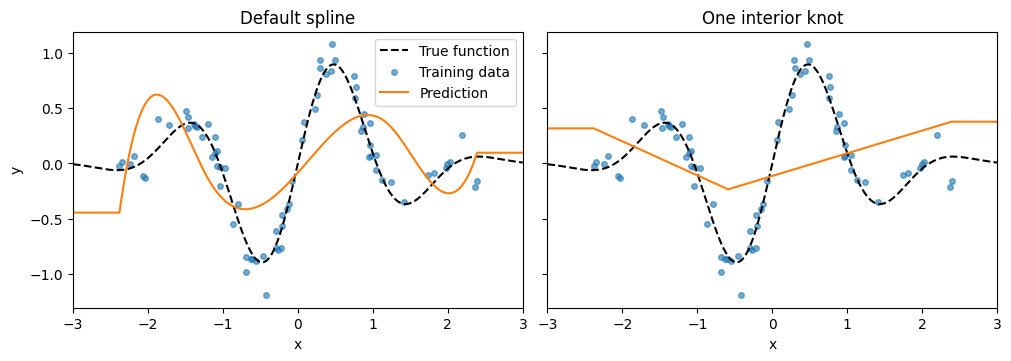

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True, layout="constrained")
for ax, model, title in zip(
    axes, (spline, best_spline), ("Default spline", "One interior knot")
):
    ax.plot(x, y, "--", color="black", label="True function")
    ax.scatter(x_train, y_train, s=16, alpha=0.6, label="Training data")
    ax.plot(x, model.predict(x[:, None]), color="tab:orange", label="Prediction")
    ax.set(xlim=(-3, 3), xlabel="x", title=title)

axes[0].set_ylabel("y")
axes[0].legend()
plt.show()

### Бустинг

При квадратичной ошибке на шаге $m$ новая модель $f_m(x)$ учится предсказывать остатки $y - F_{m-1}(x)$, после чего её прогноз добавляется к текущему с коэффициентом $\eta$:

$$
F_m(x) = F_{m-1}(x) + \eta f_m(x)
$$


На каждом шаге мы обучаем новую ломаную на текущих остатках и прибавляем к прогнозам ансамбля. Узел важно выбирать заново: если оставить его на месте, сумма ломаных так и останется ломаной с одним перегибом. С новым узлом очередная модель добавляет изгиб туда, где ошибка ещё велика, — на графиках ниже будет видно, как с ростом числа шагов прогноз постепенно повторяет исходную функцию, пока валидационная ошибка падает.

Реализуйте бустинг на сплайнах:

1. Начните с константного прогноза $\bar y_{\rm train}$. На каждом шаге обучайте `fit_best_spline` на текущих остатках обучающей выборки и прибавляйте её прогноз с коэффициентом $\eta = 0.8$.
2. После каждого шага, включая стартовый, считайте MSE на валидационной выборке (`x_val`, `y_val`). Останавливайте обучение, если минимум валидационной MSE не обновлялся 40 шагов подряд, но делайте не более 600 шагов. Итоговым считайте ансамбль с минимальной валидационной MSE.
3. Постройте график валидационной MSE по шагам и отметьте лучший шаг. На других графиках сравните исходную функцию, обучающие точки и прогнозы ансамбля на диапазоне `x` на 1%, 3%, 10%, 30% и 100%-м процентилях шагов от первого до лучшего (с округлением до целых шагов).

In [ ]:
# your code here

## Задача 2. Цена бриллианта

Поработаем с датасетом [Diamonds](https://ggplot2.tidyverse.org/reference/diamonds.html) — в нём собраны цены почти 54 тысяч бриллиантов. Будем предсказывать цену в долларах по массе, размерам и трём категориальным признакам: качеству огранки (`cut`), цвету (`color`) и чистоте (`clarity`).

Загрузим данные, удалим точные дубликаты и отложим 25% наблюдений в тестовую выборку.

In [ ]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv"
df = pd.read_csv(url).drop_duplicates()

X = df.drop(columns="price")
y = df["price"]
categorical_columns = ["cut", "color", "clarity"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


Сравните три способа кодирования категориальных признаков для `LGBMRegressor` с параметрами по умолчанию. Используйте одно и то же разбиение данных, а числовые признаки оставьте как есть:

1. **One-hot.** Закодируйте `cut`, `color` и `clarity` с помощью `OneHotEncoder`.
2. **Ordinal.** Используйте `OrdinalEncoder`, задав порядок категорий от худшей оценки к лучшей:
   - `cut`: `Fair`, `Good`, `Very Good`, `Premium`, `Ideal`;
   - `color`: `J`, `I`, `H`, `G`, `F`, `E`, `D`;
   - `clarity`: `I1`, `SI2`, `SI1`, `VS2`, `VS1`, `VVS2`, `VVS1`, `IF`.
3. **Встроенная обработка.** Приведите эти три столбца к неупорядоченному типу `category` — [LightGBM распознаёт такие столбцы](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMRegressor.html) как категориальные по умолчанию.

Обучайте кодировщики только на обучающей выборке. Сведите тестовую MAE всех трёх моделей в одну таблицу и сравните результаты.

In [ ]:
# your code here